In [1]:
# Setup
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from helpers.backtest import (
    align_prices,
    load_ntsg_usd,
    load_prices,
    monthly_rebalanced_returns,
    splice_proxy_to_actual,
    summary_metrics,
    weekly_returns,
)

OUTPUT_DIR = Path("outputs")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)
MODEL_TICKERS = ("NTSG", "COM", "DBMF", "GDE", "TAIL")
MODEL_WEIGHTS = pd.Series({"NTSG": 0.60, "COM": 0.10, "DBMF": 0.15, "GDE": 0.10, "TAIL": 0.05})
BENCHMARK_WEIGHTS = pd.Series({"VT": 0.60, "BNDW": 0.40})
EQUITY_BENCHMARK = "MSCI World Price USD"
WINDOW = 52
INFLATION_WINDOW = 36
DOWNLOAD_DATES = "Yahoo Finance/MSCI: 2026-09-30; FRED CPI: 2026-10-01"


def period_label(values: pd.Series | pd.DataFrame) -> str:
    """Format the observed period of one plotted series."""
    values = values.dropna()
    return f"{values.index.min():%Y-%m-%d}–{values.index.max():%Y-%m-%d}"


def finish_figure(fig: plt.Figure, filename: str, caption: str, bottom: float = 0.10) -> None:
    """Add a reproducibility caption, save the chart, and display it."""
    fig.subplots_adjust(bottom=bottom)
    fig.text(0.01, 0.012, caption, ha="left", va="bottom", wrap=True, fontsize=7)
    fig.savefig(IMAGE_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()


def weekly_price_returns(prices: pd.Series) -> pd.Series:
    """Return complete Friday-labelled weekly returns."""
    weekly_prices = prices.resample("W-FRI").last().dropna()
    if weekly_prices.index[-1] > prices.index[-1]:
        weekly_prices = weekly_prices.iloc[:-1]
    return weekly_prices.pct_change()


def plot_rolling_correlations(series: dict[str, pd.Series], filename: str, caption: str) -> None:
    """Plot rolling weekly correlations with the USD equity benchmark."""
    benchmark = weekly_returns("MSCI_WORLD_USD.CSV", EQUITY_BENCHMARK)
    fig, axes = plt.subplots(len(series), 1, figsize=(12, 2.5 * len(series)), sharex=True)
    for axis, (name, prices) in zip(axes, series.items()):
        correlation = weekly_price_returns(prices).rolling(WINDOW).corr(benchmark).dropna()
        axis.plot(correlation.index, correlation, linewidth=1.3)
        axis.axhline(0, color="black", linewidth=0.8)
        axis.xaxis.set_major_locator(mdates.YearLocator(base=5))
        axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        axis.tick_params(axis="x", labelbottom=True)
        axis.set(title=f"{name} vs {EQUITY_BENCHMARK} ({period_label(correlation)})", ylabel="Correlation", ylim=(-1, 1))
        axis.grid(axis="y", alpha=0.3)
    fig.suptitle(f"{WINDOW}-week rolling correlation of weekly returns", y=0.995)
    fig.tight_layout(rect=(0, 0.05, 1, 0.98))
    finish_figure(fig, filename, caption)


def plot_cumulative_total_returns(series: dict[str, pd.Series], filename: str, caption: str) -> None:
    """Plot each series' cumulative return from its first available observation."""
    fig, axes = plt.subplots(len(series), 1, figsize=(12, 2.5 * len(series)), sharex=True)
    for axis, (name, prices) in zip(axes, series.items()):
        cumulative_return = (prices / prices.iloc[0] - 1) * 100
        axis.plot(cumulative_return.index, cumulative_return, linewidth=1.3)
        axis.axhline(0, color="black", linewidth=0.8)
        axis.xaxis.set_major_locator(mdates.YearLocator(base=5))
        axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        axis.tick_params(axis="x", labelbottom=True)
        axis.set(title=f"{name}: cumulative total return ({period_label(prices)})", ylabel="Return (%)")
        axis.grid(axis="y", alpha=0.3)
    fig.suptitle("Cumulative total return from each series' first observation", y=0.995)
    fig.tight_layout(rect=(0, 0.05, 1, 0.98))
    finish_figure(fig, filename, caption)


def monthly_price_returns(prices: pd.Series) -> pd.Series:
    """Return complete month-end price returns."""
    return prices.resample("ME").last().pct_change()


def year_over_year_inflation() -> pd.Series:
    """Return the year-over-year percentage change in US CPI."""
    cpi = load_prices("CPIAUCSL.CSV", "US CPI").resample("ME").last()
    return cpi.pct_change(12) * 100


def plot_inflation_correlations(series: dict[str, pd.Series], filename: str, caption: str) -> None:
    """Plot rolling correlations of monthly asset returns with US CPI inflation."""
    inflation = year_over_year_inflation()
    fig, axes = plt.subplots(len(series), 1, figsize=(12, 2.5 * len(series)), sharex=True)
    for axis, (name, prices) in zip(axes, series.items()):
        aligned = pd.concat([inflation, monthly_price_returns(prices)], axis=1).dropna()
        correlation = aligned.iloc[:, 0].rolling(INFLATION_WINDOW).corr(aligned.iloc[:, 1]).dropna()
        axis.plot(correlation.index, correlation, linewidth=1.3)
        axis.axhline(0, color="black", linewidth=0.8)
        axis.xaxis.set_major_locator(mdates.YearLocator(base=5))
        axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        axis.tick_params(axis="x", labelbottom=True)
        axis.set(title=f"{name} vs US CPI inflation ({period_label(correlation)})", ylabel="Correlation", ylim=(-1, 1))
        axis.grid(axis="y", alpha=0.3)
    fig.suptitle(f"{INFLATION_WINDOW}-month rolling correlation: monthly asset return vs US CPI inflation", y=0.995)
    fig.tight_layout(rect=(0, 0.05, 1, 0.98))
    finish_figure(fig, filename, caption)


def year_over_year_asset_returns(prices: pd.Series) -> pd.Series:
    """Return trailing 12-month asset returns aligned to year-over-year CPI."""
    return prices.resample("ME").last().pct_change(12) * 100


def plot_inflation_and_asset_returns(series: dict[str, pd.Series], filename: str, caption: str) -> None:
    """Plot US CPI inflation and trailing 12-month returns for each asset."""
    inflation = year_over_year_inflation()
    fig, axes = plt.subplots(len(series), 1, figsize=(12, 2.5 * len(series)), sharex=True)
    for axis, (name, prices) in zip(axes, series.items()):
        aligned = pd.concat([inflation, year_over_year_asset_returns(prices)], axis=1).dropna()
        inflation_line = axis.plot(aligned.index, aligned.iloc[:, 0], color="tab:red", linewidth=1.3, label="US CPI inflation (YoY)")
        returns_axis = axis.twinx()
        return_line = returns_axis.plot(aligned.index, aligned.iloc[:, 1], color="tab:blue", linewidth=1.3, label="Asset return (12M)")
        returns_axis.axhline(0, color="black", linewidth=0.8)
        axis.xaxis.set_major_locator(mdates.YearLocator(base=5))
        axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        axis.tick_params(axis="x", labelbottom=True)
        axis.set(title=f"{name}: return vs US CPI inflation ({period_label(aligned)})", ylabel="CPI inflation (%)")
        returns_axis.set_ylabel("Asset return (%)")
        axis.legend(inflation_line + return_line, [line.get_label() for line in inflation_line + return_line], loc="upper left")
        axis.grid(axis="y", alpha=0.3)
    fig.suptitle("Trailing 12-month asset return vs US CPI inflation", y=0.995)
    fig.tight_layout(rect=(0, 0.05, 1, 0.98))
    finish_figure(fig, filename, caption)


## 1. Rolling correlations with global equities

Weekly adjusted-price returns are sampled from complete Friday-labelled weeks. The benchmark is the MSCI World **price** index in USD, so it excludes dividends, emerging markets, and small caps. NTSG is converted from its EUR listing to USD before comparison.

Each estimate uses 52 observations. The actual-ETF histories are short, non-synchronous closing times remain, and the resulting curves are descriptive rather than evidence of stable diversification.

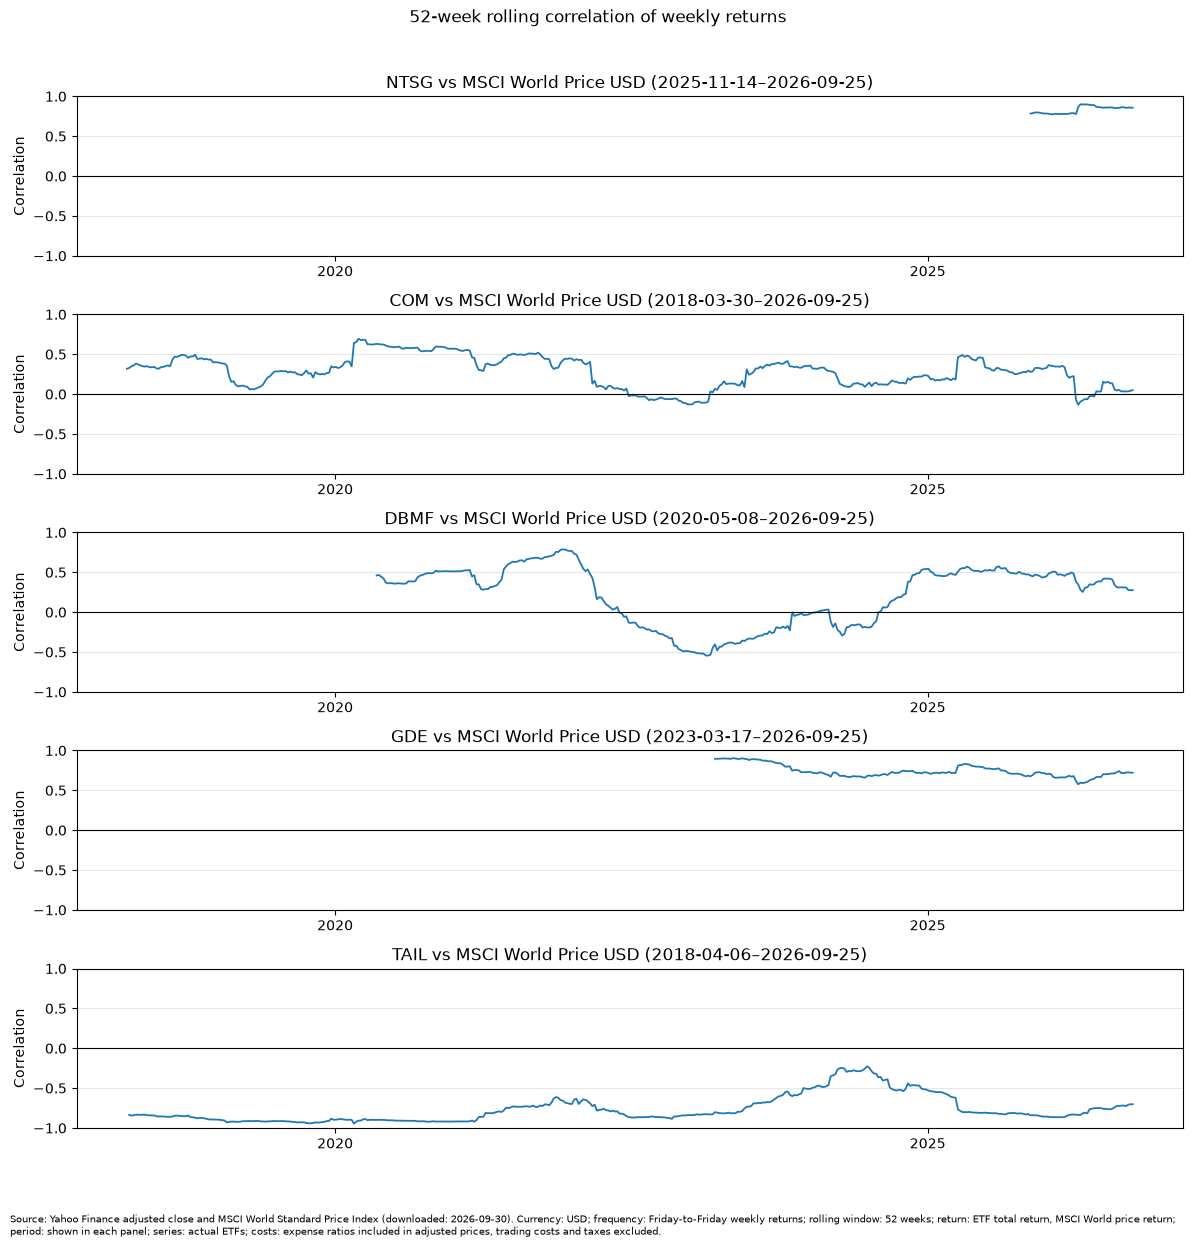

In [2]:
# Actual ETF histories, all expressed in USD.
actual_correlation_prices = {
    ticker: load_ntsg_usd() if ticker == "NTSG" else load_prices(f"{ticker}.CSV", ticker)
    for ticker in MODEL_TICKERS
}
plot_rolling_correlations(
    actual_correlation_prices,
    "52 correlation actual etfs.png",
    "Source: Yahoo Finance adjusted close and MSCI World Standard Price Index (downloaded: 2026-09-30). "
    "Currency: USD; frequency: Friday-to-Friday weekly returns; rolling window: 52 weeks; "
    "return: ETF total return, MSCI World price return; period: shown in each panel; "
    "series: actual ETFs; costs: expense ratios included in adjusted prices, trading costs and taxes excluded.",
)


### Underlying exposure proxies

These are broad descriptive proxies, not reconstructions of the model ETFs. They follow the project proxy set: VT, BNDW, PDBC, WTMF, SPY, GLD, and actual TAIL. Their holdings, leverage, duration, roll rules, and inception dates differ from the portfolio instruments.

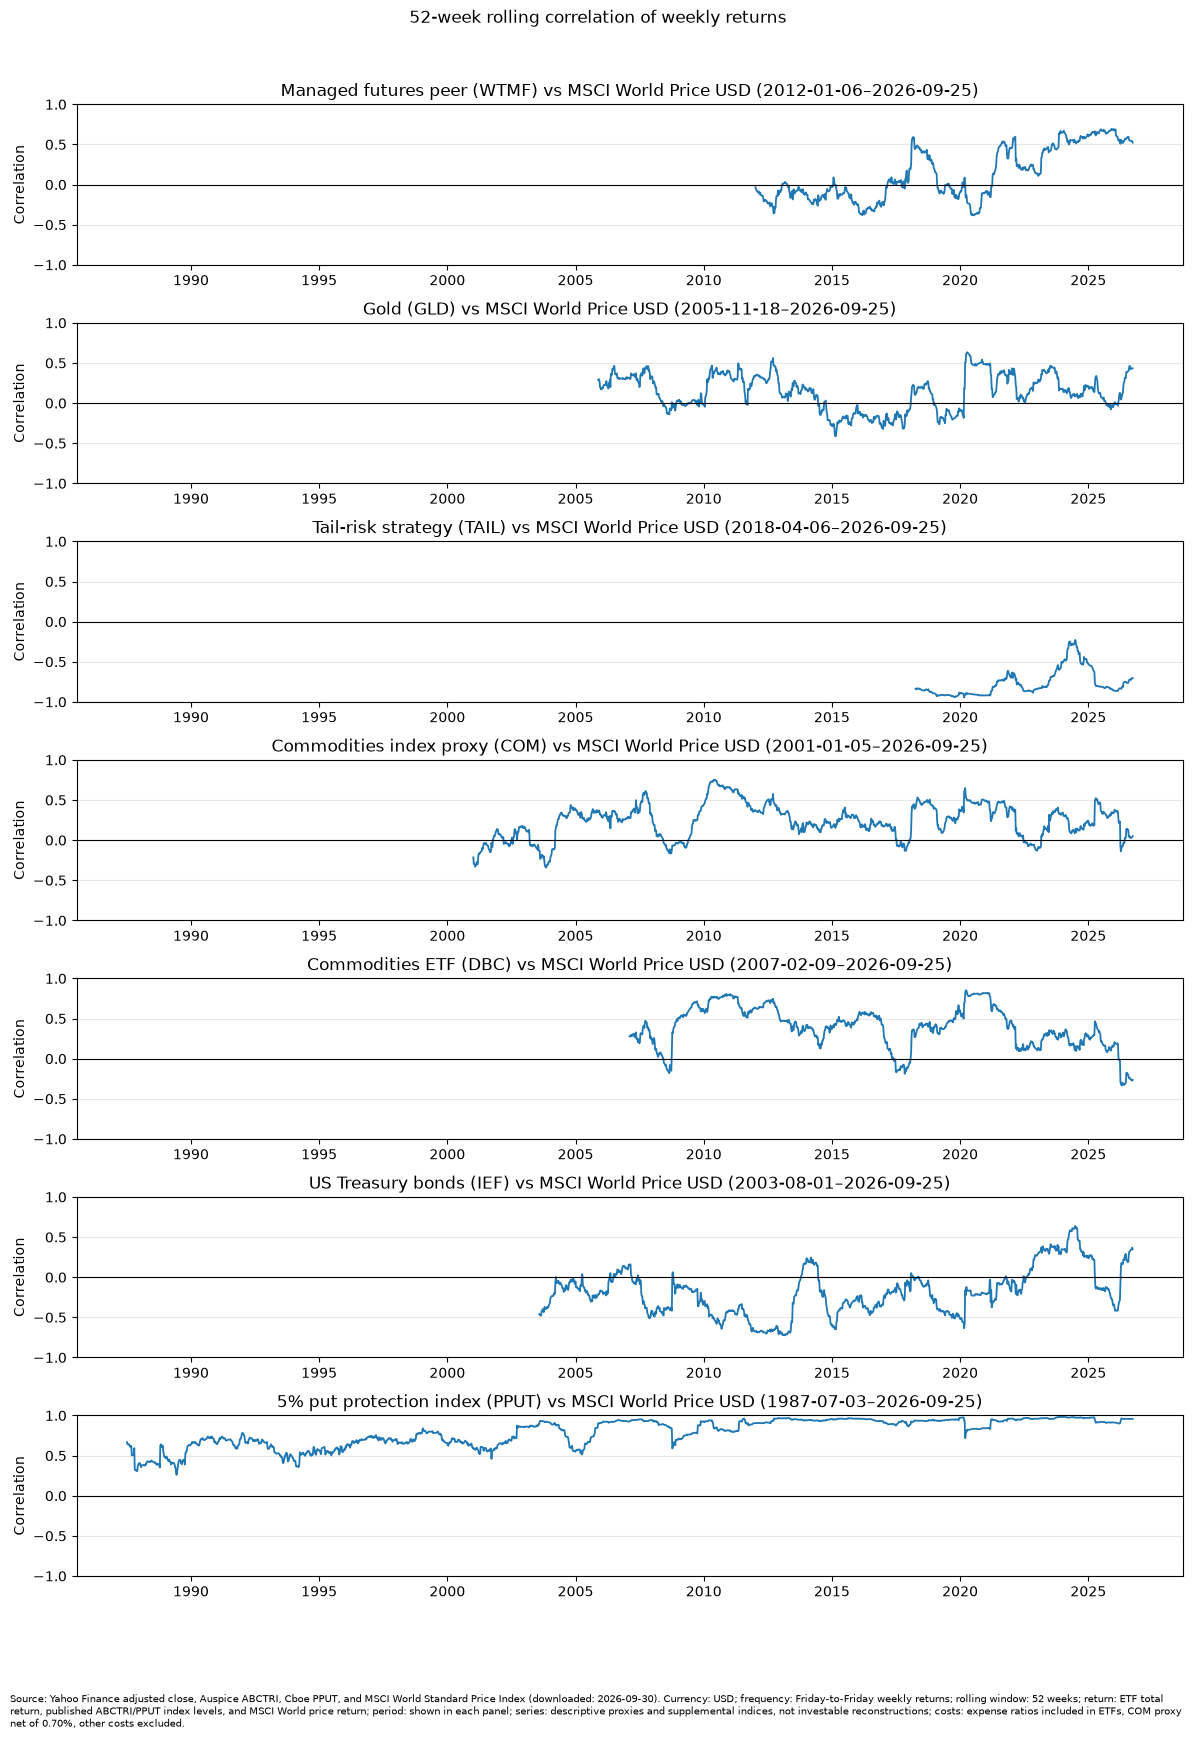

In [3]:
# Broad exposure proxies from the project specification.
underlying_prices = {
    #"Global equities (VT)": load_prices("VT.CSV", "VT"),
    #"Global bonds (BNDW)": load_prices("BNDW.CSV", "BNDW"),
    #"Broad commodities (PDBC)": load_prices("PDBC.CSV", "PDBC"),
    "Managed futures peer (WTMF)": load_prices("WTMF.CSV", "WTMF"),
    #"US large-cap equities (SPY)": load_prices("SPY.CSV", "SPY"),
    "Gold (GLD)": load_prices("GLD.CSV", "GLD"),
    "Tail-risk strategy (TAIL)": load_prices("TAIL.CSV", "TAIL"),
    "Commodities index proxy (COM)": load_prices("COM_proxy.csv", "COM proxy"),
    "Commodities ETF (DBC)": load_prices("DBC.CSV", "DBC"),
#"Global government bonds (BWX)": load_prices("BWX.CSV", "BWX"),
    "US Treasury bonds (IEF)": load_prices("IEF.CSV", "IEF"),
    "5% put protection index (PPUT)": load_prices("PPUT.CSV", "PPUT"),
}
inflation_correlation_prices = {
    "Commodities index proxy (COM)": underlying_prices["Commodities index proxy (COM)"],
    "Managed futures peer (WTMF)": underlying_prices["Managed futures peer (WTMF)"],
    #"Global government bonds (BWX)": underlying_prices["Global government bonds (BWX)"],
}
plot_rolling_correlations(
    underlying_prices,
    "underlying exposure proxies correlation.png",
    "Source: Yahoo Finance adjusted close, Auspice ABCTRI, Cboe PPUT, and MSCI World Standard Price Index (downloaded: 2026-09-30). "
    "Currency: USD; frequency: Friday-to-Friday weekly returns; rolling window: 52 weeks; "
    "return: ETF total return, published ABCTRI/PPUT index levels, and MSCI World price return; period: shown in each panel; "
    "series: descriptive proxies and supplemental indices, not investable reconstructions; costs: expense ratios included in ETFs, COM proxy net of 0.70%, other costs excluded.",
)


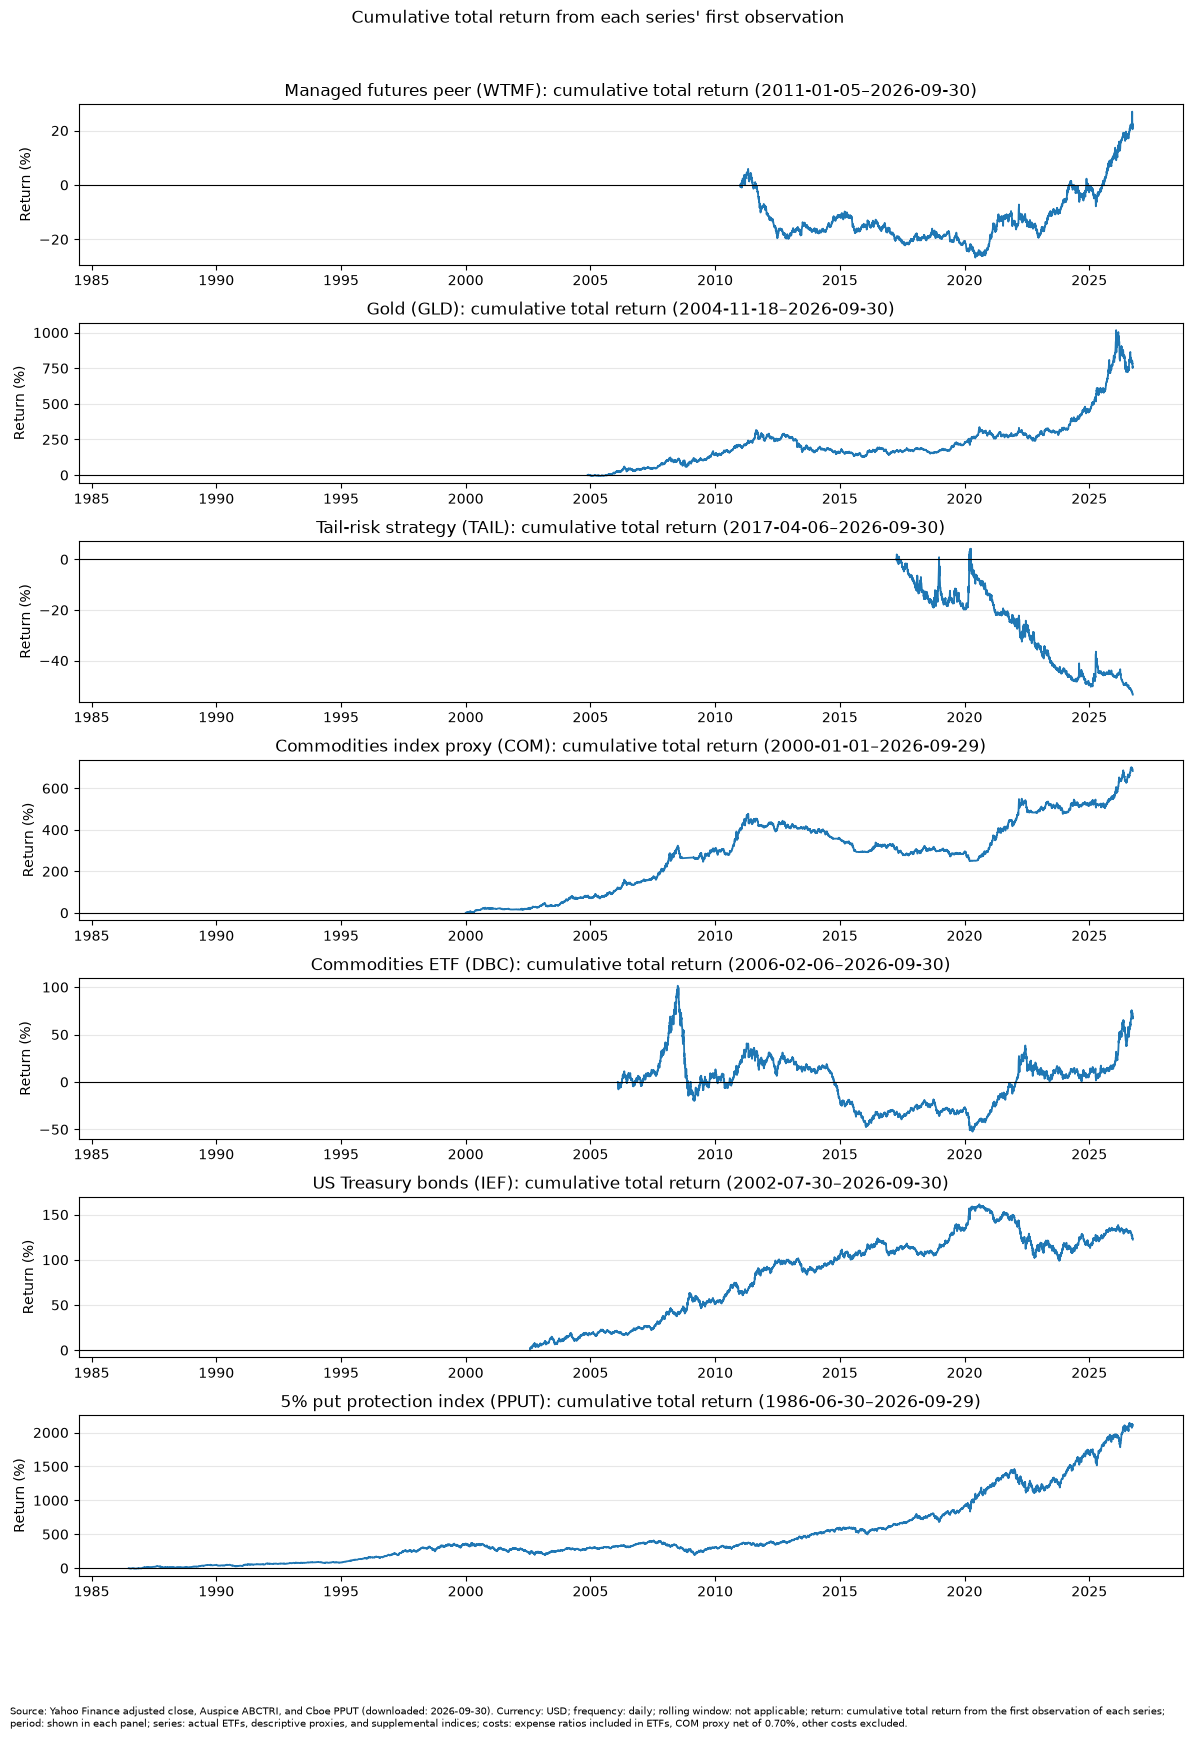

In [4]:
# Cumulative total returns for the same underlying-exposure series.
plot_cumulative_total_returns(
    underlying_prices,
    "underlying exposure proxies total return.png",
    "Source: Yahoo Finance adjusted close, Auspice ABCTRI, and Cboe PPUT (downloaded: 2026-09-30). "
    "Currency: USD; frequency: daily; rolling window: not applicable; return: cumulative total return from the first observation of each series; "
    "period: shown in each panel; series: actual ETFs, descriptive proxies, and supplemental indices; "
    "costs: expense ratios included in ETFs, COM proxy net of 0.70%, other costs excluded.",
)


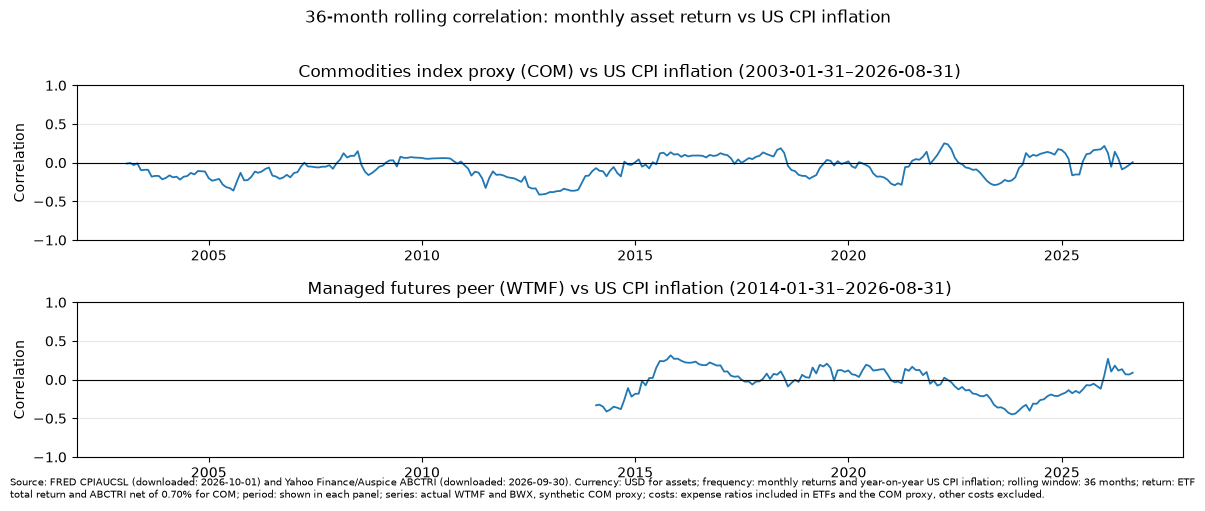

In [5]:
# Monthly asset-return correlations with year-over-year US CPI inflation.
plot_inflation_correlations(
    inflation_correlation_prices,
    "correlation vsinflation.png",
    "Source: FRED CPIAUCSL (downloaded: 2026-10-01) and Yahoo Finance/Auspice ABCTRI (downloaded: 2026-09-30). "
    "Currency: USD for assets; frequency: monthly returns and year-on-year US CPI inflation; rolling window: 36 months; "
    "return: ETF total return and ABCTRI net of 0.70% for COM; period: shown in each panel; "
    "series: actual WTMF and BWX, synthetic COM proxy; costs: expense ratios included in ETFs and the COM proxy, other costs excluded.",
)


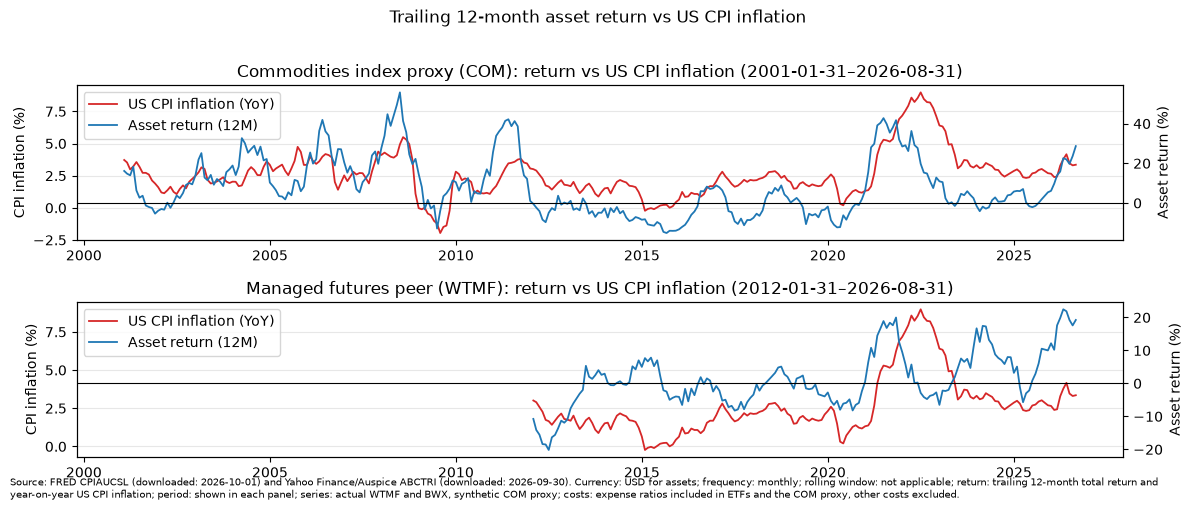

In [6]:
# Trailing 12-month asset returns compared with year-over-year US CPI inflation.
plot_inflation_and_asset_returns(
    inflation_correlation_prices,
    "asset returns vs inflation.png",
    "Source: FRED CPIAUCSL (downloaded: 2026-10-01) and Yahoo Finance/Auspice ABCTRI (downloaded: 2026-09-30). "
    "Currency: USD for assets; frequency: monthly; rolling window: not applicable; "
    "return: trailing 12-month total return and year-on-year US CPI inflation; period: shown in each panel; "
    "series: actual WTMF and BWX, synthetic COM proxy; costs: expense ratios included in ETFs and the COM proxy, other costs excluded.",
)


### Methodology for the plotted series

All lines show 52-week rolling Pearson correlations of complete Friday-to-Friday returns against the USD MSCI World **price** index. ETF observations are Yahoo Finance adjusted closes, which include distributions and each fund's expenses; the index and proxy series use their published or constructed levels. The chart is descriptive: different closing times, return definitions, currencies, holdings, durations, and histories can all affect the estimates.

| Plot label | Series type and methodology | Important limitation |
| --- | --- | --- |
| Global equities (VT) | Actual total-return ETF proxy for global, market-cap weighted equities, including developed and emerging markets. | The MSCI World benchmark excludes emerging markets and dividends. |
| Global bonds (BNDW) | Actual total-return ETF proxy for global investment-grade bonds. | Short history; sector, currency, and duration exposures differ from NTSG's government-bond futures sleeve. |
| Broad commodities (PDBC) | Actual total-return ETF following a rules-based, diversified commodity-futures strategy. | Contract selection, collateral, and roll rules differ from COM and a broad commodity spot basket. |
| Managed futures peer (WTMF) | Actual total-return ETF for a diversified managed-futures strategy. | A peer, not DBMF: its signals, markets, risk targets, and positions differ. |
| US large-cap equities (SPY) | Actual total-return ETF tracking the S&P 500. | US large caps only, not global equities. |
| Gold (GLD) | Actual total-return ETF backed by allocated gold bullion, net of fund expenses. | Physical-gold exposure differs from GDE's gold-futures sleeve. |
| Tail-risk strategy (TAIL) | Actual total-return ETF: mostly US Treasuries plus a dynamically sized ladder of long out-of-the-money SPX puts. | Short history; its discretionary sizing and option implementation cannot be reproduced from public information. |
| Commodities index proxy (COM) | Auspice Broad Commodity **Total Return** Index (`ABCTRI`), normalized to 100 and compounded net of COM's 0.70% annual expense ratio: $V_t = V_{t-1}(ABCTRI_t / ABCTRI_{t-1})(1 - 0.007/365)^{d_t}$. It contains futures price, roll, and collateral returns. | 2000 through 2010-09-29 is issuer-simulated; the live index is still not fund NAV. |
| Commodities ETF (DBC) | Actual total-return commodity-futures ETF using the Deutsche Bank Optimum Yield roll approach. | A different commodity universe, roll selection, and collateral implementation from COM. |
| Global government bonds (BWX) | Actual total-return ETF holding non-US sovereign bonds, with local-currency and FX effects. | It is international government debt, not a global aggregate-bond index or NTSG's futures basket. |
| US Treasury bonds (IEF) | Actual total-return ETF holding US Treasury notes with roughly 7-10 years remaining maturity. | US-only intermediate duration; not a global bond proxy. |
| 5% put protection index (PPUT) | Cboe index holding an S&P 500 equity portfolio and buying a one-month, 5% out-of-the-money SPX put, normally rolled monthly. | It embeds a large equity allocation and is therefore a protective-put benchmark, not a TAIL proxy. |

The longest histories improve the range of market regimes shown, but do not make the proxy returns investable model-portfolio history. The backtests retain actual DBMF and TAIL data rather than using a supplemental-series backfill.

### Analisi dei grafici di correlazione

- **WTMF, almeno fino al 2022, non ha esibito una correlazione stabile con MSCI World: intuizione sostanzialmente corretta, ma da qualificare.** Dal primo dato rolling disponibile nel 2012 alla fine del 2021, la correlazione media è stata -0,04 e la mediana -0,09; è risultata positiva solo nel 31% delle osservazioni. Non è però rimasta sempre vicina a zero: nello stesso intervallo ha oscillato tra -0,38 e 0,59, passando per circa -0,25 a fine 2015, 0,20 a fine 2018 e 0,45 a fine 2021. Nel 2022 è tornata verso 0,13, mentre negli anni successivi è salita fino a valori superiori a 0,6. Questo comportamento è coerente con una strategia managed futures che può assumere posizioni lunghe o corte in azioni, tassi, valute e commodity: la bassa correlazione è una proprietà media e dipendente dal regime e dalle posizioni correnti, non una caratteristica costante né una garanzia di protezione durante ogni ribasso azionario.

- **Le azioni large cap statunitensi mostrano dal 2006 una correlazione quasi pari a 1 con MSCI World: intuizione corretta, senza però un vero punto di rottura strutturale nel 2006.** Dal 2006 la correlazione rolling media di SPY è 0,96, il minimo è 0,88 e il 96% delle osservazioni supera 0,90. Era circa 0,93 a fine 2006, 0,96 durante la crisi del 2008, 0,99 durante lo shock Covid e 0,98 a fine 2022. 

- **L'oro non è rimasto sempre tra 0 e 0,5: l'intuizione sulla correlazione generalmente contenuta è corretta, ma l'intervallo indicato è troppo ristretto.** La correlazione rolling di GLD ha una mediana di 0,15, ma nel campione varia da -0,41 nel febbraio 2015 a 0,63 nell'aprile 2020. Era quasi nulla a fine 2008, è diventata negativa in parte del 2013-2018, ha superato 0,6 durante lo shock Covid, era circa 0,25 a fine 2022 ed è tornata leggermente negativa a fine 2025.  non è quindi un hedge azionario permanente: dollaro, tassi reali, inflazione, domanda di liquidità e acquisti difensivi possono dominarne il prezzo in momenti diversi. Può proteggere durante alcuni shock, ma in una finestra rolling di 52 settimane può anche muoversi nella stessa direzione delle azioni.

- **TAIL presenta una correlazione negativa con MSCI World: intuizione corretta; la spiegazione basata su un rendimento necessariamente negativo negli anni azionari positivi è invece troppo forte.** Nel campione rolling disponibile dal 2018 la correlazione resta sempre negativa, con mediana -0,83 e intervallo da -0,95 a -0,23; vale circa -0,89 durante il crollo Covid e -0,84 a fine 2022. Il segno negativo è coerente con i put SPX, che acquistano valore nei ribassi, ma la correlazione misura la co-variazione settimanale e non il rendimento medio del fondo. Nei mercati rialzisti il premio pagato e il decadimento temporale delle opzioni costituiscono effettivamente un carry negativo; tuttavia TAIL detiene soprattutto Treasury e dimensiona dinamicamente i put, quindi tassi, duration e volatilità possono produrre rendimenti positivi o negativi indipendentemente dal semplice segno del rendimento azionario.

- **Le commodity mostrano spesso correlazioni moderate, ma non rimangono sempre tra 0 e 0,5; il calo intorno al 2022 è evidente, mentre quello del 2008 dipende dalla strategia e dalla fase osservata.** Il proxy COM varia da -0,34 a 0,75, mentre DBC e PDBC raggiungono circa -0,35 e 0,85. Nel 2022, quando il MSCI World price index perse circa il 19,5%, l'inflazione e lo shock energetico successivo all'invasione dell'Ucraina sostennero molte commodity: tra fine 2021 e fine 2022 la correlazione scese da 0,41 a -0,13 per COM e da circa 0,48 a 0,11 per DBC/PDBC. Nel 2008, anno in cui MSCI World perse circa il 42%, COM era vicino a zero, ma DBC passò da -0,07 a metà anno a 0,47 a fine anno: dopo il picco delle materie prime, il collasso della domanda e la liquidazione simultanea degli attivi rischiosi fecero scendere insieme azioni e commodity. La diversificazione fu quindi maggiore nella fase iniziale e nella successiva ripresa, non durante tutta la crisi; inoltre COM può essere long o flat, mentre DBC e PDBC sono esposizioni commodity long-only con regole di roll differenti.

## 2. Portfolio backtests

Daily adjusted prices are expressed in USD and aligned to one common calendar. Short market-holiday gaps are forward-filled; gaps longer than five observations are dropped. Portfolios rebalance at month-end close and exclude trading costs and taxes.

Benchmarks are a monthly rebalanced 60% VT / 40% BNDW portfolio and 100% VT. Sharpe and Sortino use the effective federal funds rate as cash. Results include worst calendar-year and one-year rolling-return statistics, but the actual-ETF window remains too short for reliable inference.

In [7]:
# Shared benchmark and cash series.
BENCHMARK_PRICES = pd.concat(
    [load_prices("VT.CSV", "VT"), load_prices("BNDW.CSV", "BNDW")], axis=1, sort=True
)
CASH_PRICES = load_prices("USD_CASH_EFFR.CSV", "USD cash")


def run_comparison(
    model_prices: pd.DataFrame,
    title: str,
    summary_file: str,
    image_file: str,
    caption: str,
) -> pd.DataFrame:
    """Compare all strategies on one aligned daily calendar."""
    prices = align_prices(pd.concat([model_prices, BENCHMARK_PRICES], axis=1, sort=True))
    returns = pd.DataFrame({
        "Model portfolio": monthly_rebalanced_returns(prices, MODEL_WEIGHTS),
        "60/40 VT/BNDW": monthly_rebalanced_returns(prices, BENCHMARK_WEIGHTS),
        "VT": prices["VT"].pct_change().fillna(0.0),
    })
    if returns.isna().any().any():
        raise ValueError("Strategies do not share a complete return calendar.")

    metrics = pd.DataFrame({name: summary_metrics(returns[name], CASH_PRICES) for name in returns}).T
    metrics.index.name = "Strategy"
    metrics.to_csv(OUTPUT_DIR / summary_file)
    print(f"{title}: {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")
    display(metrics)
    ax = ((1 + returns).cumprod().sub(1) * 100).plot(
        figsize=(12, 4), linewidth=1.5, grid=True, title=f"{title}: cumulative total return (%)"
    )
    fig = ax.get_figure()
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.16), ncol=3, borderaxespad=0.0)
    fig.subplots_adjust(top=0.76)
    finish_figure(fig, image_file, caption + f" Period: {period_label(returns)}.", bottom=0.30)
    return returns


### 2a. Actual ETFs only

This is the least assumption-heavy test, but it begins in November 2024 and contains too little history for robust conclusions. NTSG is converted from its EUR listing to USD with daily EURUSD. Its Xetra close precedes the US close, so daily covariance, volatility, and drawdown remain timing-noisy.

NTSG 2024-11-13 to 2026-09-30: 18.99% in EUR, 27.03% in USD
Actual ETF backtest: 2024-11-13 to 2026-09-30


,Cumulative return,CAGR,Volatility,Max drawdown,Max drawdown period,Sharpe,Sortino,Calmar,Worst calendar year,Worst calendar year return,1Y rolling return (5th percentile),1Y rolling return (median),1Y rolling return (95th percentile)
Strategy,,,,,,,,,,,,,
Model portfolio,0.31506,0.156993,0.108574,-0.106836,2025-02-18 to 2025-04-09,1.023994,1.459349,1.469477,2025,0.229822,0.158718,0.229156,0.293899
60/40 VT/BNDW,0.22227,0.112784,0.099104,-0.098772,2025-02-18 to 2025-04-08,0.718515,1.046084,1.14186,2025,0.152653,0.109594,0.149758,0.210263
VT,0.362733,0.179139,0.15754,-0.165145,2025-02-18 to 2025-04-08,0.867196,1.277951,1.084734,2025,0.224339,0.170503,0.230173,0.340095


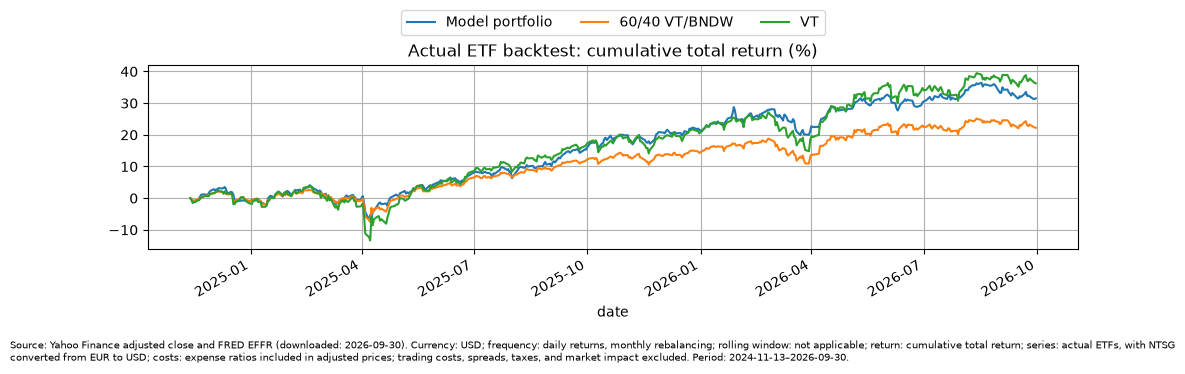

In [8]:
# Actual ETF portfolio.
ntsg_eur = load_prices("NTSG.CSV", "NTSG EUR")
ntsg_usd = load_ntsg_usd()
print(
    f"NTSG {ntsg_eur.index[0]:%Y-%m-%d} to {ntsg_eur.index[-1]:%Y-%m-%d}: "
    f"{ntsg_eur.iloc[-1] / ntsg_eur.iloc[0] - 1:.2%} in EUR, "
    f"{ntsg_usd.iloc[-1] / ntsg_usd.iloc[0] - 1:.2%} in USD"
)
actual_prices = pd.concat(
    [
        ntsg_usd,
        load_prices("COM.CSV", "COM"),
        load_prices("DBMF.CSV", "DBMF"),
        load_prices("GDE.CSV", "GDE"),
        load_prices("TAIL.CSV", "TAIL"),
    ],
    axis=1,
    sort=True,
)
actual_returns = run_comparison(
    actual_prices,
    "Actual ETF backtest",
    "actual_etf_backtest_summary.csv",
    "real total return.png",
    "Source: Yahoo Finance adjusted close and FRED EFFR (downloaded: 2026-09-30). Currency: USD; frequency: daily returns, "
    "monthly rebalancing; rolling window: not applicable; return: cumulative total return; series: actual ETFs, with NTSG converted from EUR to USD; "
    "costs: expense ratios included in adjusted prices; trading costs, spreads, taxes, and market impact excluded.",
)


### 2b. Synthetic sensitivity

This is a counterfactual exposure test, not investable historical performance. NTSG and GDE use present-day strategy approximations before fund inception and are spliced to actual returns afterward. The fixed NTSG regional weights, current methodologies, and current fees introduce look-ahead bias whose direction is unknown.

DBMF and TAIL are not backfilled because their disclosed rules are insufficient for reconstruction. DBMF therefore fixes the common start at May 2019. COM already existed by then, so its synthetic history is unnecessary and actual COM is used throughout.

Synthetic sensitivity: 2019-05-08 to 2026-09-30


,Cumulative return,CAGR,Volatility,Max drawdown,Max drawdown period,Sharpe,Sortino,Calmar,Worst calendar year,Worst calendar year return,1Y rolling return (5th percentile),1Y rolling return (median),1Y rolling return (95th percentile)
Strategy,,,,,,,,,,,,,
Model portfolio,1.252581,0.116026,0.127361,-0.224204,2020-02-19 to 2020-03-23,0.704441,0.975573,0.517504,2022,-0.142026,-0.106573,0.137279,0.289359
60/40 VT/BNDW,0.808725,0.083405,0.116804,-0.223456,2020-02-12 to 2020-03-23,0.503122,0.69204,0.373253,2022,-0.157555,-0.136687,0.114046,0.231068
VT,1.486705,0.131044,0.186979,-0.342362,2020-02-12 to 2020-03-23,0.601934,0.836658,0.382765,2022,-0.180033,-0.158945,0.169998,0.37943


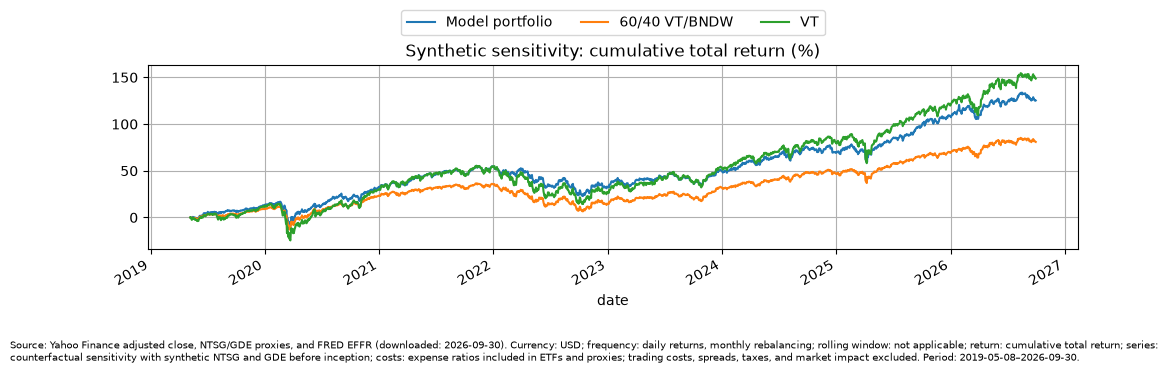

In [9]:
# Synthetic NTSG and GDE before inception; all other legs are actual ETFs.
extended_prices = pd.concat(
    [
        splice_proxy_to_actual("NTSG_proxy_extended.csv", ntsg_usd),
        load_prices("COM.CSV", "COM"),
        load_prices("DBMF.CSV", "DBMF"),
        splice_proxy_to_actual("GDE_proxy.csv", load_prices("GDE.CSV", "GDE")),
        load_prices("TAIL.CSV", "TAIL"),
    ],
    axis=1,
    sort=True,
)
extended_returns = run_comparison(
    extended_prices,
    "Synthetic sensitivity",
    "proxy_extended_backtest_summary.csv",
    "synthetic total return.png",
    "Source: Yahoo Finance adjusted close, NTSG/GDE proxies, and FRED EFFR (downloaded: 2026-09-30). Currency: USD; frequency: daily returns, "
    "monthly rebalancing; rolling window: not applicable; return: cumulative total return; series: counterfactual sensitivity with synthetic NTSG and GDE before inception; "
    "costs: expense ratios included in ETFs and proxies; trading costs, spreads, taxes, and market impact excluded.",
)


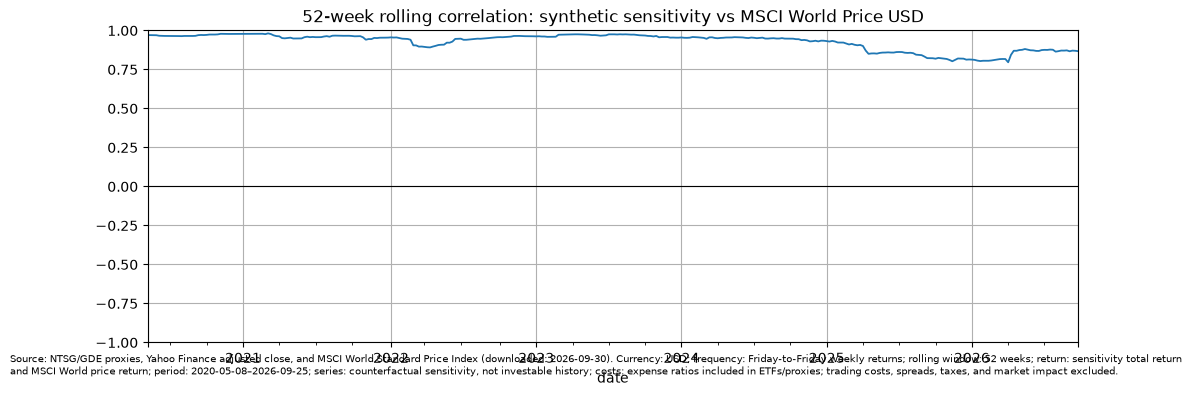

In [10]:
# Rolling equity correlation of the synthetic-sensitivity portfolio.
extended_wealth = (1 + extended_returns["Model portfolio"]).cumprod()
model_weekly = weekly_price_returns(extended_wealth)
msci_weekly = weekly_returns("MSCI_WORLD_USD.CSV", EQUITY_BENCHMARK)
model_correlation = model_weekly.rolling(WINDOW).corr(msci_weekly).dropna()
ax = model_correlation.plot(
    figsize=(12, 4),
    linewidth=1.3,
    grid=True,
    ylim=(-1, 1),
    title=f"{WINDOW}-week rolling correlation: synthetic sensitivity vs {EQUITY_BENCHMARK}",
)
ax.axhline(0, color="black", linewidth=0.8)
finish_figure(
    ax.get_figure(),
    "synthetic sensitivity rolling correlation.png",
    "Source: NTSG/GDE proxies, Yahoo Finance adjusted close, and MSCI World Standard Price Index (downloaded: 2026-09-30). "
    "Currency: USD; frequency: Friday-to-Friday weekly returns; rolling window: 52 weeks; "
    "return: sensitivity total return and MSCI World price return; period: " + period_label(model_correlation) + "; "
    "series: counterfactual sensitivity, not investable history; costs: expense ratios included in ETFs/proxies; trading costs, spreads, taxes, and market impact excluded.",
)


## Audit findings and interpretation

### Findings that could mislead conclusions

- **Selection bias:** The portfolio was selected after observing recent fund performance. The results are not out-of-sample evidence.
- **Look-ahead bias in synthetic history:** The extended NTSG and GDE series apply current strategy designs, current fees, and fixed historical proxy weights before fund inception. Their historical performance is counterfactual; the bias may be favorable or unfavorable.
- **Short actual sample:** The actual portfolio begins in November 2024. It has only one complete calendar year, so its CAGR, Sharpe, Sortino, Calmar, drawdown, and rolling statistics are unstable. The 2025 model return was 22.98%, but this is not evidence of a normal annual outcome.
- **NTSG reconstruction error:** The NTSG proxy uses broad equity and bond ETFs instead of the official ESG equity basket, sovereign futures, currency-linked weights, roll schedule, and multi-currency collateral.
- **GDE reconstruction error:** The GDE proxy uses fee-adjusted GLD minus cash instead of gold-futures returns and assumes quarterly resets that are not published fund rules.
- **Unreconstructed strategies:** DBMF's Dynamic Beta Engine and TAIL's option ladder cannot be reproduced from public information. WTMF and PPUT are peers or benchmarks, not substitutes.
- **COM simulated history:** The Auspice ABCTRI history before 2010-09-30 is issuer-simulated and benefits from hindsight. Actual COM is used in the portfolio tests.
- **Benchmark mismatch:** The model has approximately 138% gross notional exposure, while VT and the 60/40 benchmark do not. Direct CAGR comparisons therefore mix leverage, exposure design, and manager skill.
- **Currency and timing mismatch:** NTSG trades in EUR, its FX conversion and Xetra close are not synchronized with US-listed assets, and daily covariance, volatility, Sharpe, and drawdown contain non-synchronous-pricing noise.
- **Return-definition mismatch:** The correlation benchmark is the MSCI World price index, excluding dividends, while ETF prices are adjusted for distributions. Correlations describe co-movement, not total-return equivalence or downside protection.
- **Data and implementation risk:** Yahoo adjusted prices are unaudited. Holiday filling creates stale or zero-return observations, and longer missing-data gaps are dropped. Fees, spreads, commissions, taxes, market impact, futures margin changes, and option trading costs are excluded.
- **Cash-rate inconsistency:** Proxy construction uses DGS3MO, while Sharpe and Sortino use EFFR. This is an approximation, not a single consistent financing assumption.
- **Currency reporting gap:** Results are currently USD-only. The required EUR and CHF periodic-return analysis has not been implemented.

### Corrections applied

- NTSG is converted from EUR to USD before USD correlations and backtests.
- Model and benchmarks use one common daily calendar with a five-observation forward-fill limit.
- Incomplete terminal weeks and months are excluded from correlation and validation samples.
- The synthetic sensitivity backfills only NTSG and GDE. DBMF and TAIL remain actual-only; COM is actual throughout that test.
- Rolling correlations no longer use hindsight-defined crisis markers.
- Metrics now include complete-calendar-year returns, one-year rolling-return quantiles, and sample-frequency annualization.
- Futures sleeves are treated as notional profit-and-loss overlays rather than funded assets.

### Current validation facts

- Closed-month proxy correlations through August 2026 are 0.932 for NTSG, 0.987 for GDE, 0.989 for COM, and 0.279 for the WTMF-based DBMF peer.
- The actual USD backtest runs from 2024-11-13 to 2026-09-30; the synthetic sensitivity runs from 2019-05-08 to 2026-09-30.
- These figures support sensitivity analysis only. They do not establish that the model will outperform VT or 60/40 in future or investable historical periods.